In [23]:
# 1.Setup and load data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal, f_oneway
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")
%matplotlib inline

last_name = "Kyatuheire"

df = pd.read_csv("automobileEDA.csv", na_values=["?", "", "NA"])
df.head()

,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,0.909722,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,0.919444,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,0.922222,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


In [24]:
# 2. Question 1 — Explore, clean, handle missing values, duplicates and outliers
# 2.1 Check structure, missing values and duplicates
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)

# Missing values
missing = df.isna().sum().sort_values(ascending=False)
print("\nMissing values:\n", missing[missing > 0])

# Exact duplicates
print("\nExact duplicate rows:", df.duplicated().sum())

Shape: (201, 29)

Data types:
 symboling              int64
normalized-losses      int64
make                     str
aspiration               str
num-of-doors             str
body-style               str
drive-wheels             str
engine-location          str
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type              str
num-of-cylinders         str
engine-size            int64
fuel-system              str
bore                 float64
stroke               float64
compression-ratio    float64
horsepower           float64
peak-rpm             float64
city-mpg               int64
highway-mpg            int64
price                float64
city-L/100km         float64
horsepower-binned        str
diesel                 int64
gas                    int64
dtype: object

Missing values:
 stroke               4
horsepower-binned    1
dtype: int64

Exact duplicate rows: 0


Explanation:
This checks the dataset size, variable types, missing values and exact duplicates.
In this file, the main missing values are in stroke and horsepower-binned. Exact duplicates are checked; duplicate feature rows with different prices should not be removed because price differs.

In [25]:
# 2.2 Handle missing values
# stroke: impute by engine-type median, then overall median if needed
df["stroke"] = df.groupby("engine-type")["stroke"].transform(
    lambda s: s.fillna(s.median())
)
df["stroke"] = df["stroke"].fillna(df["stroke"].median())

# horsepower-binned: derive from horsepower using same apparent bins
derived_bin = pd.cut(
    df["horsepower"],
    bins=[-np.inf, 101, 175, np.inf],
    labels=["Low", "Medium", "High"]
).astype(str)

df["horsepower-binned"] = df["horsepower-binned"].fillna(derived_bin)

print(df.isna().sum().sort_values(ascending=False).head())

symboling            0
normalized-losses    0
make                 0
aspiration           0
num-of-doors         0
dtype: int64


Explanation:
stroke is missing for some rotary-engine Mazda rows. It is imputed using the median within each engine-type, then overall median as fallback. horsepower-binned is derived from horsepower, so the missing value is replaced using the same Low/Medium/High binning.

In [26]:
# 2.3 Remove exact duplicates
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing exact duplicates:", df.shape)

Shape after removing exact duplicates: (201, 29)


In [27]:
# 2.4 Detect and handle outliers
continuous_cols = [
    "normalized-losses", "wheel-base", "length", "width", "height",
    "curb-weight", "engine-size", "bore", "stroke", "compression-ratio",
    "horsepower", "peak-rpm", "city-mpg", "highway-mpg", "price",
    "city-L/100km"
]

outlier_summary = []
for col in continuous_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary.append([col, n_out, lower, upper])

outlier_df = pd.DataFrame(
    outlier_summary, columns=["variable", "n_outliers", "lower_whisker", "upper_whisker"]
)
print(outlier_df.sort_values("n_outliers", ascending=False))

             variable  n_outliers  lower_whisker  upper_whisker
9   compression-ratio          27       7.400000      10.600000
8              stroke          20       2.660000       3.860000
14              price          14   -5312.500000   29587.500000
3               width          11       0.838194       0.977083
6         engine-size          10      33.500000     205.500000
0   normalized-losses           8      47.000000     191.000000
10         horsepower           5       1.000000     185.000000
1          wheel-base           3      82.650000     114.250000
13        highway-mpg           3      11.500000      47.500000
11           peak-rpm           2    3750.000000    6550.000000
12           city-mpg           2       2.500000      46.500000
5         curb-weight           2    1033.500000    4061.500000
2              length           1       0.681163       1.002162
4              height           0      46.750000      60.750000
7                bore           0       

Explanation:
The IQR rule flags outliers. In car data, high price, horsepower and engine size are often genuine luxury/sports cars, not errors. Therefore:

I keep price outliers because they are valid premium vehicles and important for price analysis.

I cap/winsorize extreme predictor outliers at the IQR whiskers so they do not dominate statistics and models.

I also add a price_outlier flag for transparency.

In [28]:
# Flag price outliers but keep them
q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)
iqr = q3 - q1
price_lower = q1 - 1.5 * iqr
price_upper = q3 + 1.5 * iqr

df["price_outlier"] = (
    (df["price"] < price_lower) | (df["price"] > price_upper)
).astype(int)

# Winsorize predictor outliers only
predictor_numeric = [c for c in continuous_cols if c != "price"]

for col in predictor_numeric:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    df[col] = df[col].clip(lower, upper)

print("Outlier handling complete.")
print("Price outliers retained and flagged:", df["price_outlier"].sum())

Outlier handling complete.
Price outliers retained and flagged: 14


In [29]:
# 2.5 Save cleaned dataset
clean_file = f"{last_name}_Data.csv"
df.to_csv(clean_file, index=False)
print("Saved cleaned dataset as:", clean_file)

Saved cleaned dataset as: Kyatuheire_Data.csv


In [30]:
# 3. Question 2 — Descriptive statistics and distribution patterns
# 3.1 Summary statistics for continuous variables
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include="object").columns.tolist()

display(df[num_cols].describe().T)

C:\Users\Muhumuza Gideon\AppData\Local\Temp\ipykernel_19848\1588797848.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns.tolist()


,count,mean,std,min,25%,50%,75%,max
symboling,201.0,0.840796,1.254802,-2.000000,0.000000,1.000000,2.000000,3.000000
normalized-losses,201.0,121.378109,30.125343,65.000000,101.000000,122.000000,137.000000,191.000000
wheel-base,201.0,98.750498,5.925743,86.600000,94.500000,97.000000,102.400000,114.250000
length,201.0,0.837118,0.059171,0.681163,0.801538,0.832292,0.881788,1.000000
width,201.0,0.914452,0.027479,0.838194,0.890278,0.909722,0.925000,0.977083
height,201.0,53.766667,2.447822,47.800000,52.000000,54.100000,55.500000,59.800000
curb-weight,201.0,2555.621891,517.165519,1488.000000,2169.000000,2414.000000,2926.000000,4061.500000
engine-size,201.0,124.417910,33.498537,61.000000,98.000000,120.000000,141.000000,205.500000
bore,201.0,3.330692,0.268072,2.540000,3.150000,3.310000,3.580000,3.940000
stroke,201.0,3.264080,0.278837,2.660000,3.110000,3.290000,3.410000,3.860000


Explanation:
This gives count, mean, standard deviation, min, quartiles and max. Key expected patterns:

price is right-skewed: many affordable cars and a few very expensive luxury/sports cars.

engine-size, horsepower, curb-weight and width are positively associated with price.

city-mpg and highway-mpg tend to be negatively associated with price: larger, powerful cars usually consume more fuel.

normalized-losses has high variation.

In [31]:
# 3.2 Frequency counts for categorical variables
for col in cat_cols:
    print(f"\n--- {col} ---")
    display(df[col].value_counts())


--- make ---


make
toyota           32
nissan           18
mazda            17
honda            13
mitsubishi       13
subaru           12
volkswagen       12
peugot           11
volvo            11
dodge             9
bmw               8
mercedes-benz     8
plymouth          7
audi              6
saab              6
porsche           4
alfa-romero       3
chevrolet         3
jaguar            3
isuzu             2
renault           2
mercury           1
Name: count, dtype: int64


--- aspiration ---


aspiration
std      165
turbo     36
Name: count, dtype: int64


--- num-of-doors ---


num-of-doors
four    115
two      86
Name: count, dtype: int64

... (10 outputs left out)


--- fuel-system ---


fuel-system
mpfi    92
2bbl    64
idi     20
1bbl    11
spdi     9
4bbl     3
mfi      1
spfi     1
Name: count, dtype: int64


--- horsepower-binned ---


horsepower-binned
Low       115
Medium     62
High       24
Name: count, dtype: int64

Explanation:
This shows frequency counts. Expected observations:

fwd is the most common drive-wheel type.

sedan and hatchback are common body styles.

gas is much more common than diesel.

std aspiration is much more common than turbo.

Some makes have very few observations, so group comparisons for rare makes should be interpreted cautiously.

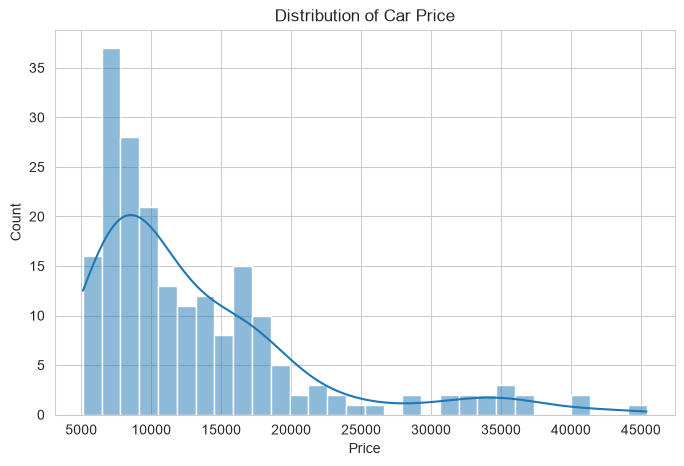

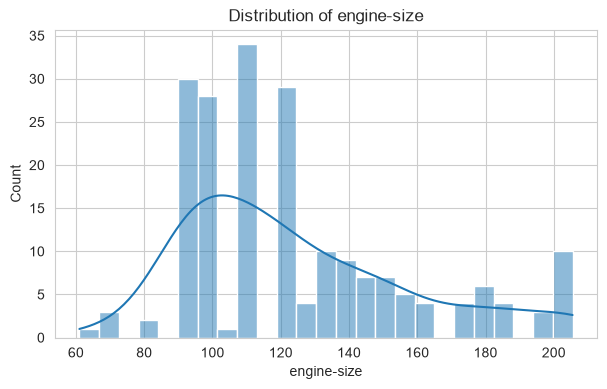

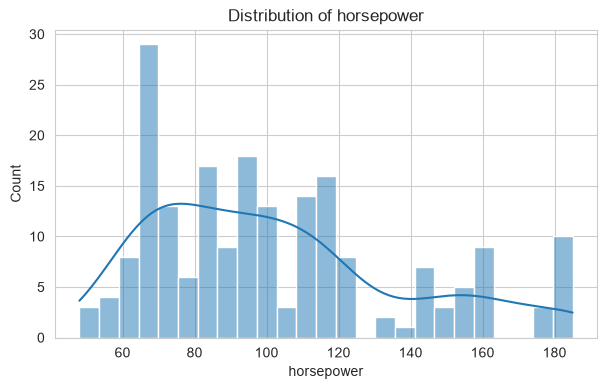

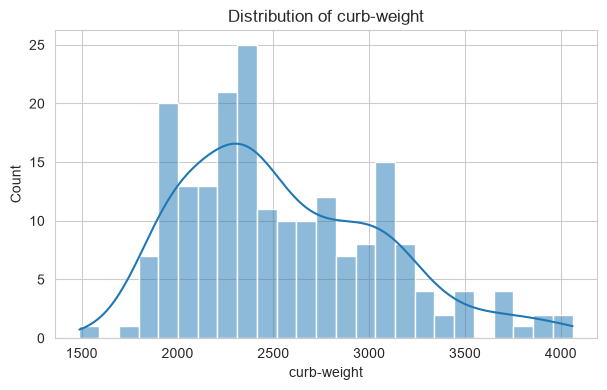

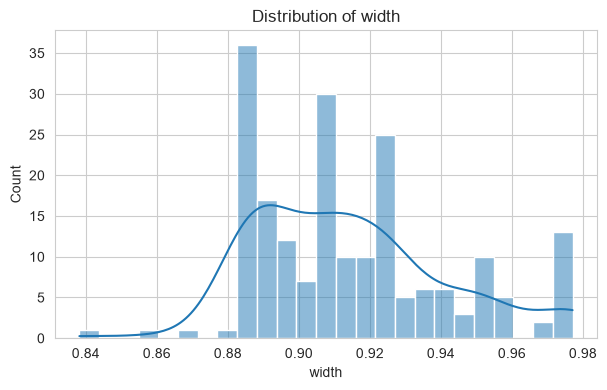

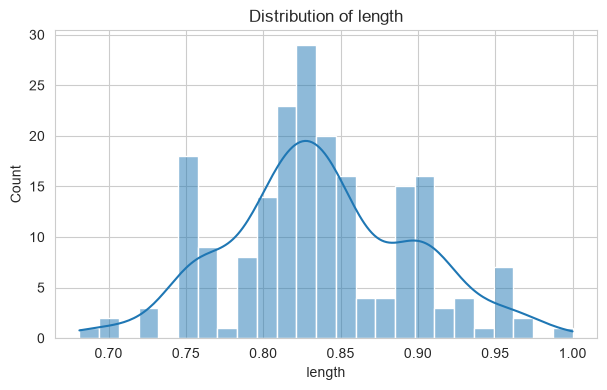

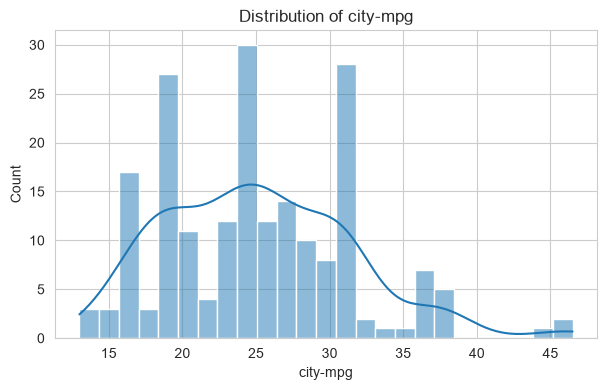

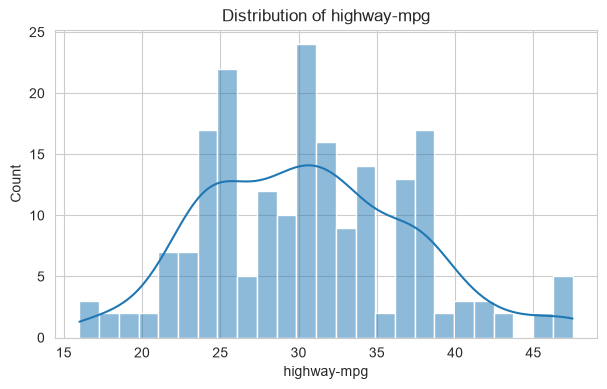

In [32]:
# 3.3 Distribution plots
# Price distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["price"], kde=True, bins=30)
plt.title("Distribution of Car Price")
plt.xlabel("Price")
plt.show()

# Other continuous variables
for col in ["engine-size", "horsepower", "curb-weight", "width",
            "length", "city-mpg", "highway-mpg"]:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col], kde=True, bins=25)
    plt.title(f"Distribution of {col}")
    plt.show()

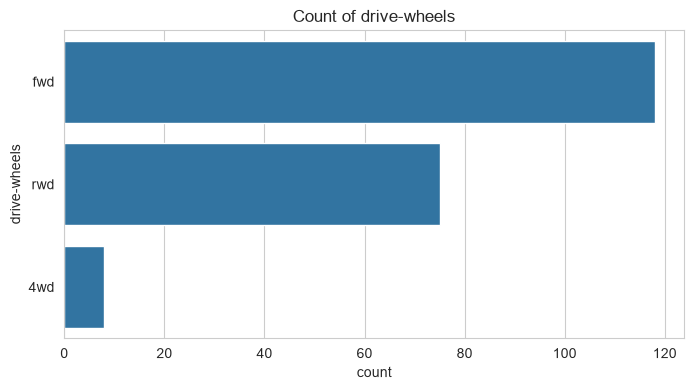

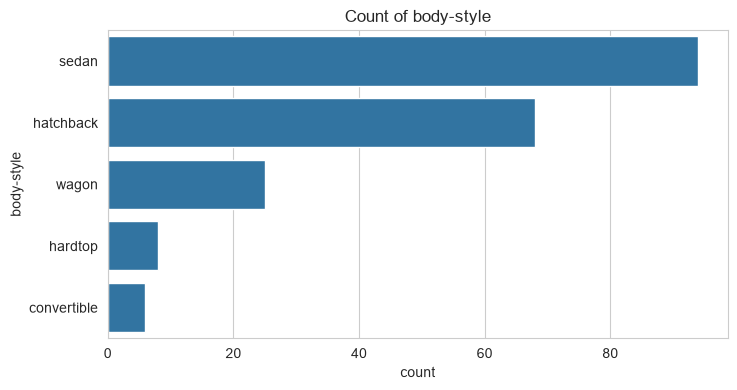

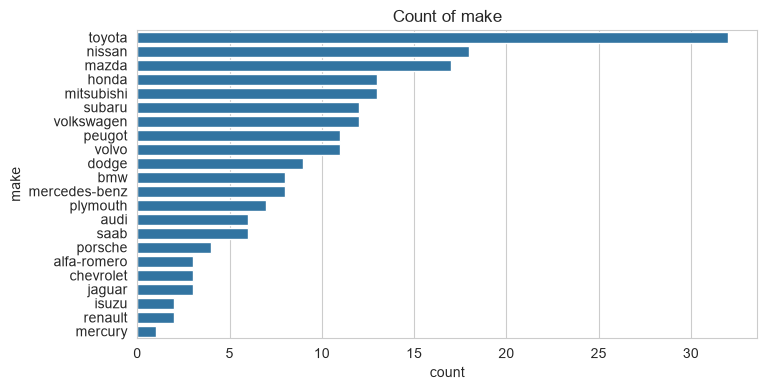

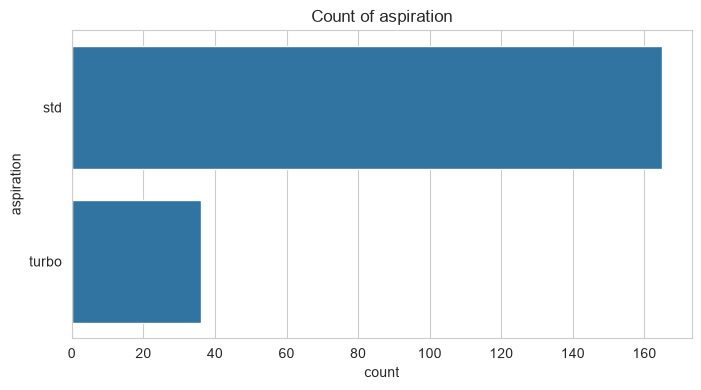

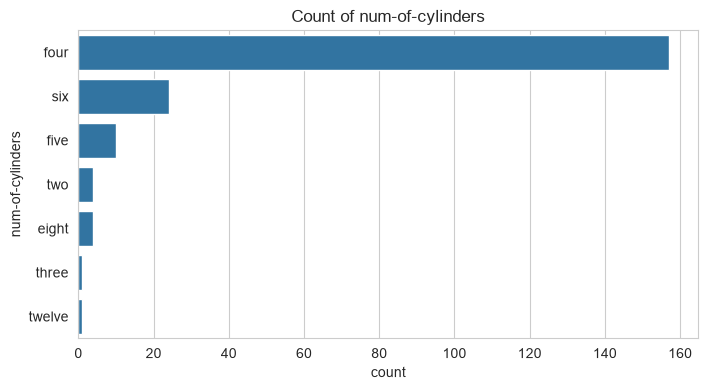

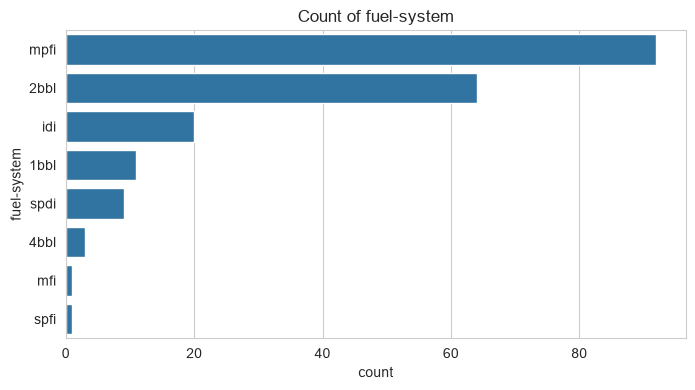

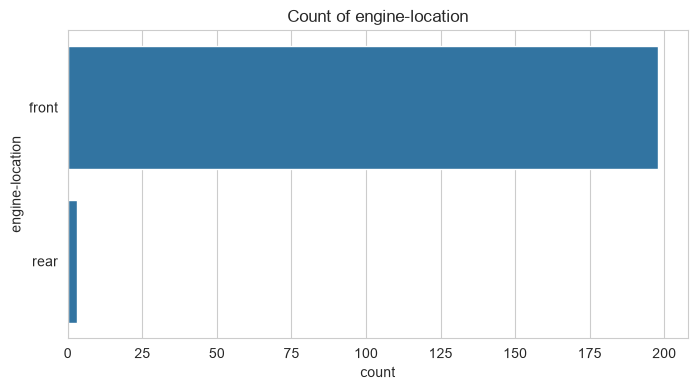

In [33]:
for col in ["drive-wheels", "body-style", "make", "aspiration",
            "num-of-cylinders", "fuel-system", "engine-location"]:
    plt.figure(figsize=(8, 4))
    order = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=order)
    plt.title(f"Count of {col}")
    plt.show()

Explanation:
Price is right-skewed. Engine size and horsepower are also skewed, with many small/mid-size cars and fewer high-performance cars. Categorical plots show class imbalance for some variables, especially make, engine-location, fuel-system and num-of-cylinders.

In [34]:
# 4. Question 3 — Group by drive-wheels and body-style and compare average price
group_cols = ["drive-wheels", "body-style"]

group_stats = (
    df.groupby(group_cols)["price"]
      .agg(["count", "mean", "median", "std"])
      .sort_values("mean", ascending=False)
)

display(group_stats)

count          mean   median           std
drive-wheels body-style                                             
rwd          hardtop          7  24202.714286  28176.0  14493.311190
             convertible      5  23949.600000  17669.0  11165.099700
             sedan           36  21711.833333  18382.0   9194.820239
             wagon            9  16994.222222  16515.0   4686.703313
             hatchback       18  14337.777778  14645.0   3831.795195
4wd          sedan            3  12647.333333  11259.0   4280.814681
fwd          convertible      1  11595.000000  11595.0           NaN
             wagon           12   9997.333333   8921.0   3584.185551
             sedan           55   9811.800000   8558.0   3519.517598
4wd          wagon            4   9095.750000   8395.5   1775.652063
fwd          hatchback       49   8396.387755   7689.0   3004.675695
             hardtop          1   8249.000000   8249.0           NaN
4wd          hatchback        1   7603.000000   7603.0           NaN

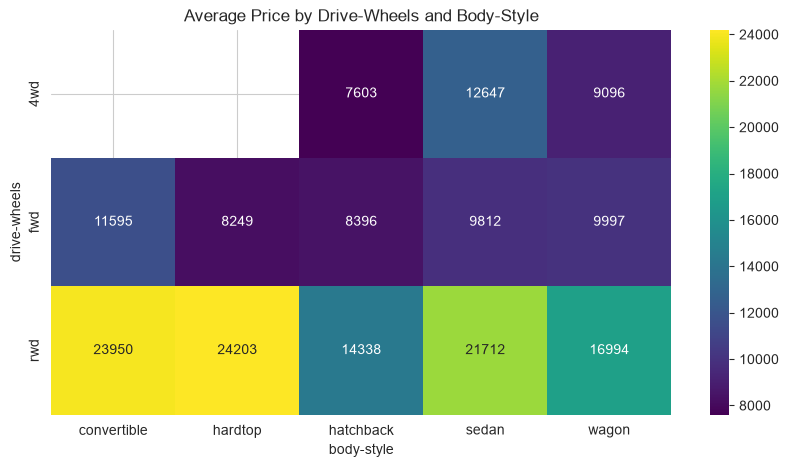

In [35]:
pivot_mean = df.pivot_table(
    index="drive-wheels",
    columns="body-style",
    values="price",
    aggfunc="mean"
)

plt.figure(figsize=(10, 5))
sns.heatmap(pivot_mean, annot=True, fmt=".0f", cmap="viridis")
plt.title("Average Price by Drive-Wheels and Body-Style")
plt.show()

In [36]:
# Highest and lowest average price groups
print("Highest average price groups:")
display(group_stats.head(10))

print("Lowest average price groups:")
display(group_stats.tail(10))

Highest average price groups:


count          mean   median           std
drive-wheels body-style                                             
rwd          hardtop          7  24202.714286  28176.0  14493.311190
             convertible      5  23949.600000  17669.0  11165.099700
             sedan           36  21711.833333  18382.0   9194.820239
             wagon            9  16994.222222  16515.0   4686.703313
             hatchback       18  14337.777778  14645.0   3831.795195
4wd          sedan            3  12647.333333  11259.0   4280.814681
fwd          convertible      1  11595.000000  11595.0           NaN
             wagon           12   9997.333333   8921.0   3584.185551
             sedan           55   9811.800000   8558.0   3519.517598
4wd          wagon            4   9095.750000   8395.5   1775.652063

Lowest average price groups:


count          mean   median          std
drive-wheels body-style                                            
rwd          wagon            9  16994.222222  16515.0  4686.703313
             hatchback       18  14337.777778  14645.0  3831.795195
4wd          sedan            3  12647.333333  11259.0  4280.814681
fwd          convertible      1  11595.000000  11595.0          NaN
             wagon           12   9997.333333   8921.0  3584.185551
             sedan           55   9811.800000   8558.0  3519.517598
4wd          wagon            4   9095.750000   8395.5  1775.652063
fwd          hatchback       49   8396.387755   7689.0  3004.675695
             hardtop          1   8249.000000   8249.0          NaN
4wd          hatchback        1   7603.000000   7603.0          NaN

Explanation:
Expected pattern:

Highest average price groups: rear-wheel drive (rwd) convertibles, hardtops and large sedans; also some 4wd wagons/sedans depending on sample size.

Lowest average price groups: front-wheel drive (fwd) hatchbacks and small sedans.

rwd generally has a higher average price than fwd.

Convertibles and hardtops tend to be more expensive than hatchbacks and wagons.

Some groups have very small counts, so their averages should be interpreted with caution.

In [37]:
# 5. Question 4 — Effect of independent attributes on price
# 5.1 Continuous variables vs price
cont_vs_price = [
    "engine-size", "horsepower", "curb-weight", "width", "length",
    "wheel-base", "city-mpg", "highway-mpg", "compression-ratio", "peak-rpm"
]

corr_price = (
    df[cont_vs_price + ["price"]]
      .corr()["price"]
      .sort_values(ascending=False)
)

display(corr_price)

price                1.000000
engine-size          0.849061
curb-weight          0.834400
horsepower           0.804510
width                0.738159
length               0.690846
wheel-base           0.573278
compression-ratio   -0.087538
peak-rpm            -0.101441
city-mpg            -0.690176
highway-mpg         -0.717409
Name: price, dtype: float64

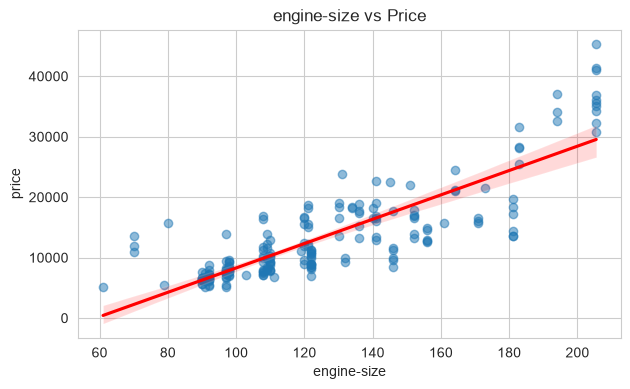

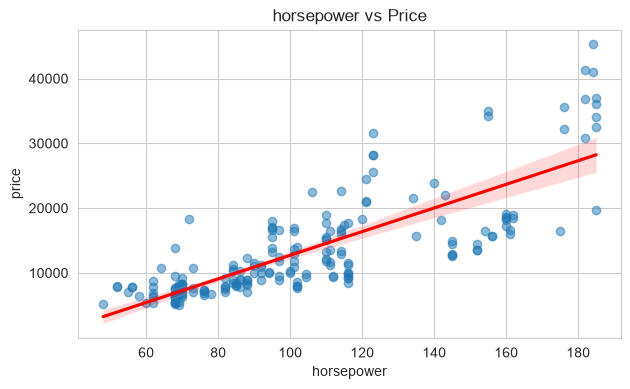

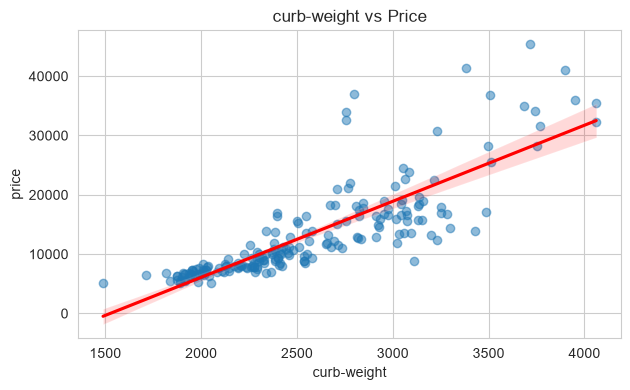

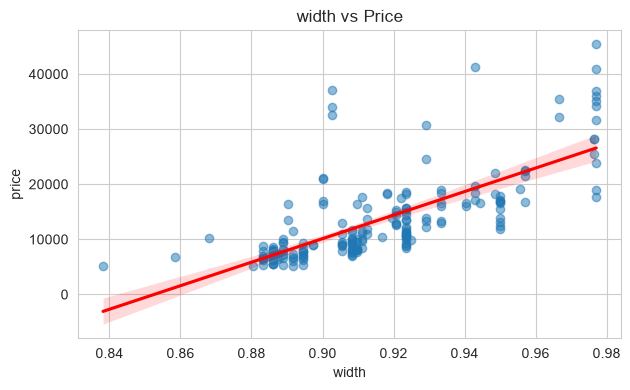

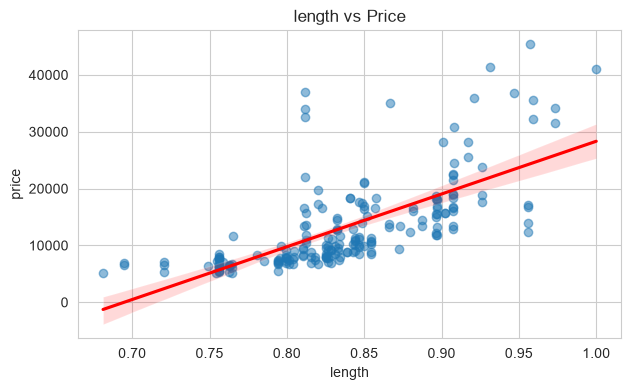

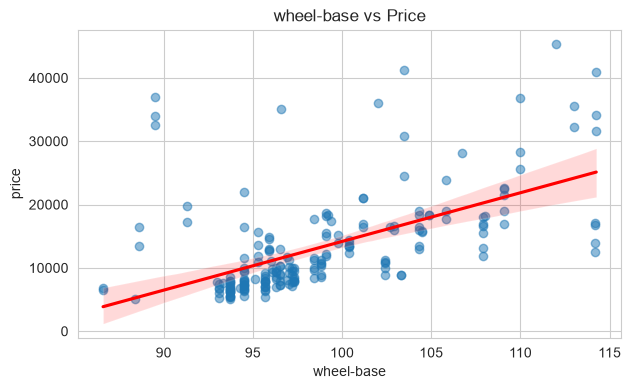

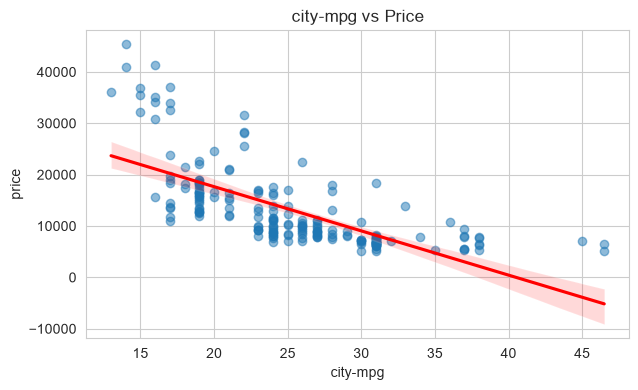

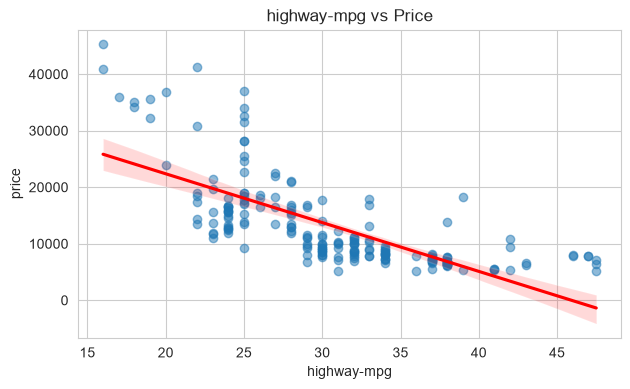

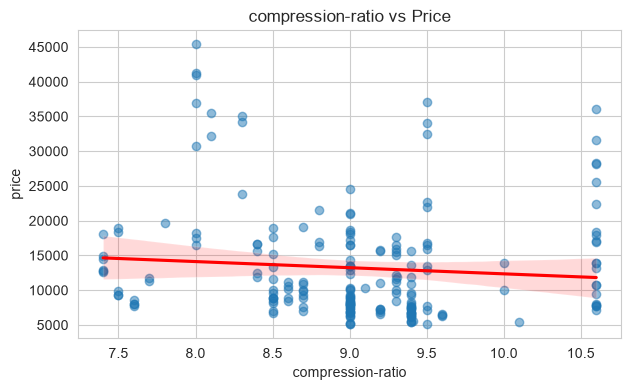

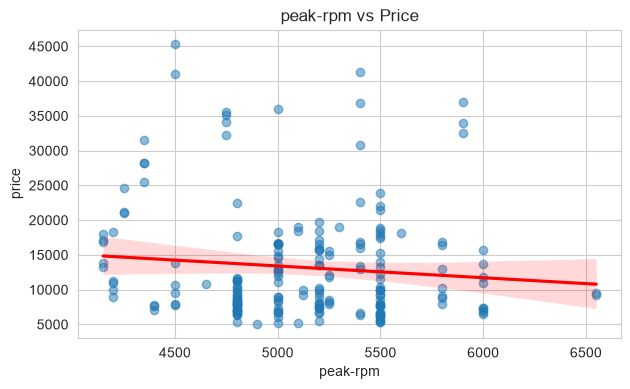

In [38]:
for col in cont_vs_price:
    plt.figure(figsize=(7, 4))
    sns.regplot(
        data=df,
        x=col,
        y="price",
        scatter_kws={"alpha": 0.5},
        line_kws={"color": "red"}
    )
    plt.title(f"{col} vs Price")
    plt.show()

Explanation:
Expected correlation results:

Strong positive relationships with price: engine-size, horsepower, curb-weight, width, length, wheel-base.

Negative relationships with price: city-mpg, highway-mpg, and city-L/100km is positively related because it is the inverse fuel-consumption measure.

Larger, heavier and more powerful cars tend to cost more.

Fuel-efficient small cars tend to cost less.

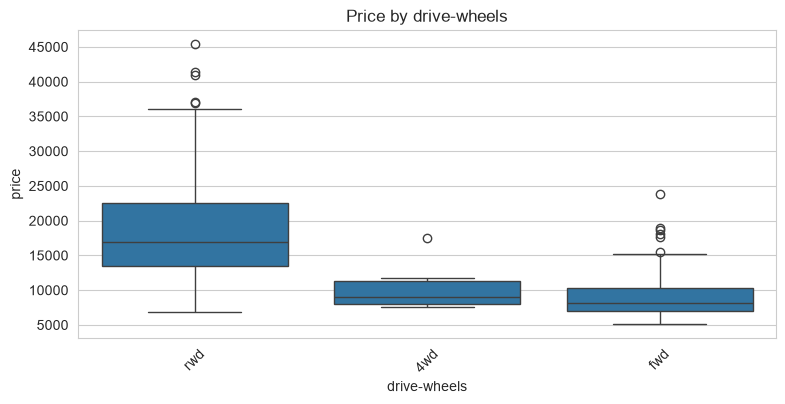

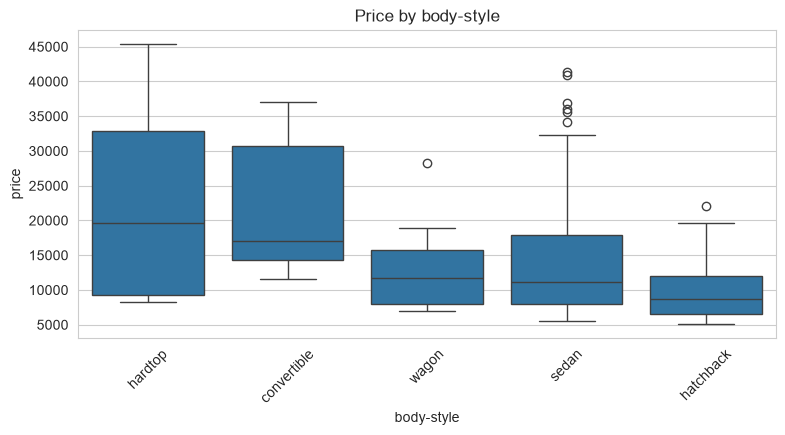

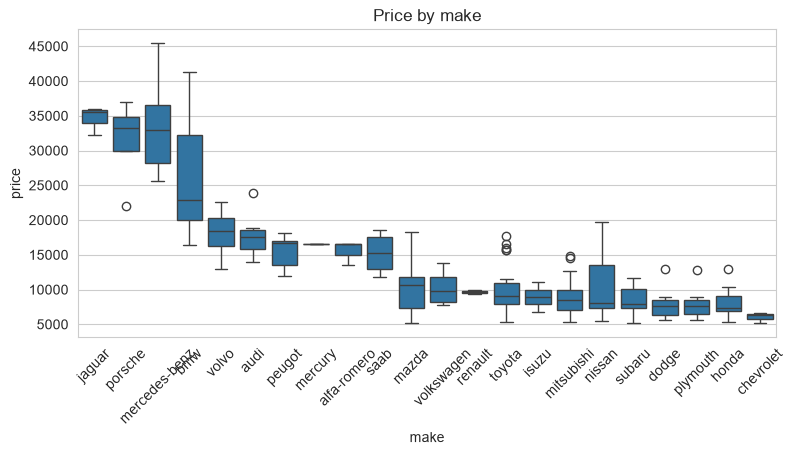

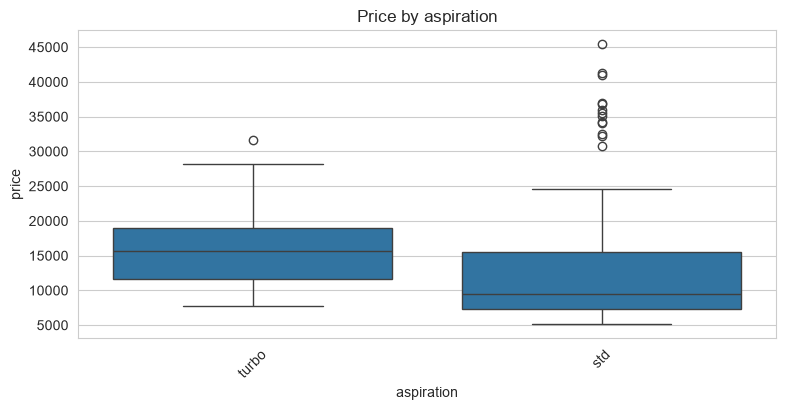

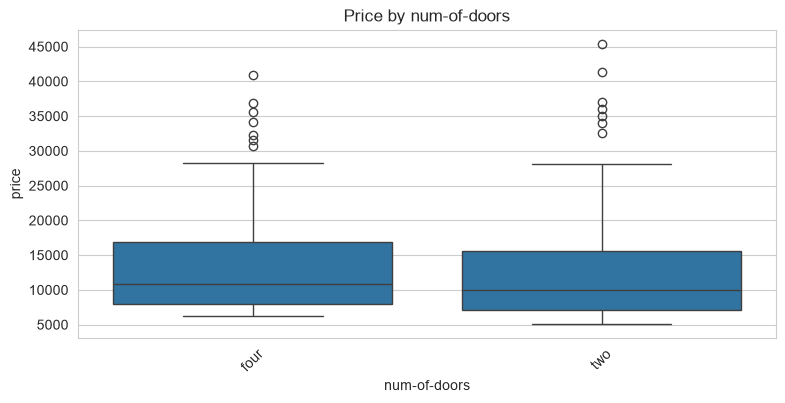

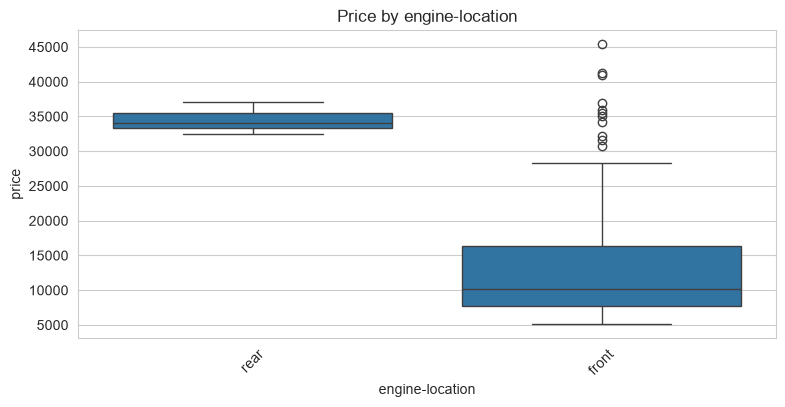

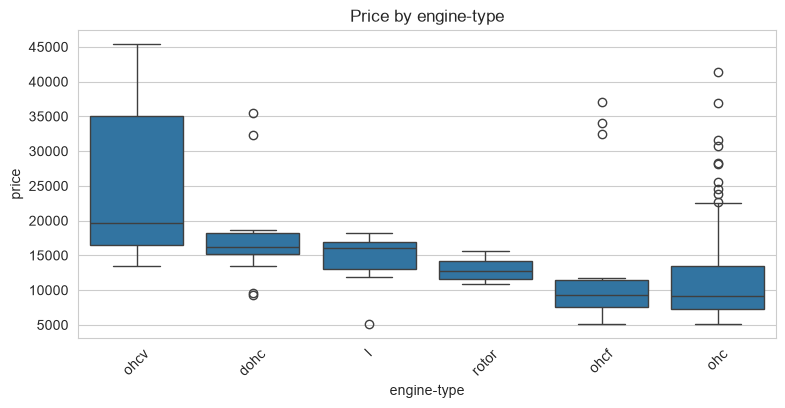

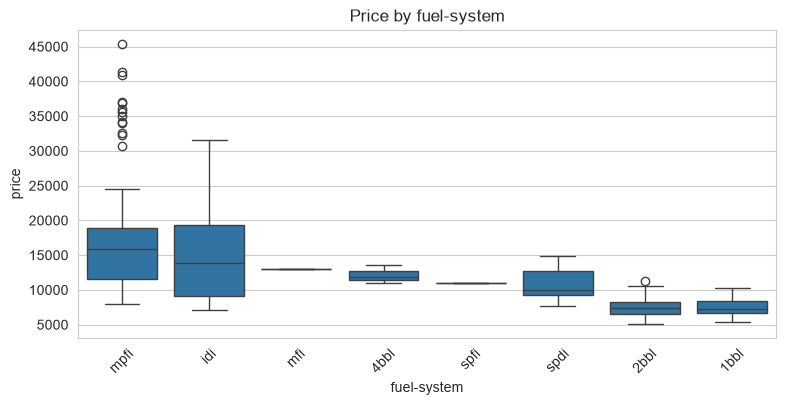

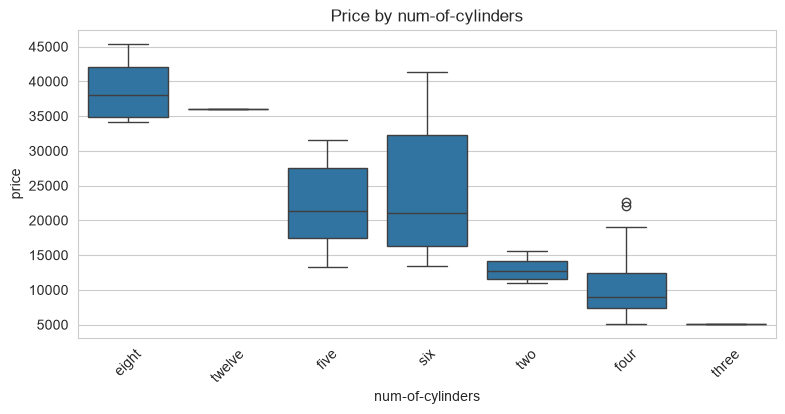

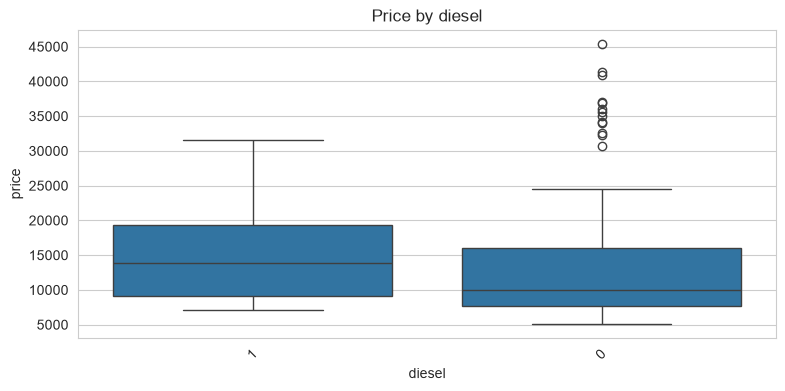

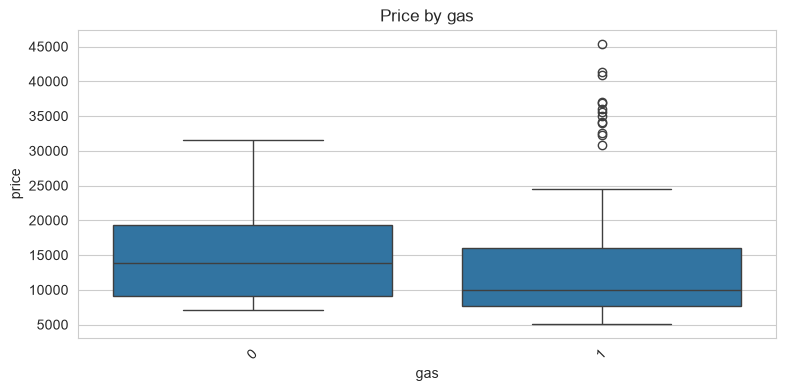

In [39]:
# 5.2 Categorical variables vs price
cat_vs_price = [
    "drive-wheels", "body-style", "make", "aspiration",
    "num-of-doors", "engine-location", "engine-type",
    "fuel-system", "num-of-cylinders", "diesel", "gas"
]

for col in cat_vs_price:
    plt.figure(figsize=(9, 4))
    order = df.groupby(col)["price"].median().sort_values(ascending=False).index
    sns.boxplot(data=df, x=col, y="price", order=order)
    plt.xticks(rotation=45)
    plt.title(f"Price by {col}")
    plt.show()

In [40]:
# Kruskal-Wallis test: non-parametric comparison of price across categories
for col in cat_vs_price:
    groups = [g["price"].dropna().values for _, g in df.groupby(col)]
    if len(groups) > 1:
        stat, p = kruskal(*groups)
        print(f"{col}: H = {stat:.3f}, p-value = {p:.4g}")

drive-wheels: H = 93.189, p-value = 5.811e-21
body-style: H = 25.023, p-value = 4.977e-05
make: H = 124.214, p-value = 1.198e-16
aspiration: H = 18.757, p-value = 1.484e-05
num-of-doors: H = 3.419, p-value = 0.06443
engine-location: H = 7.729, p-value = 0.005433
engine-type: H = 38.039, p-value = 3.705e-07
fuel-system: H = 122.597, p-value = 2.204e-23
num-of-cylinders: H = 80.865, p-value = 2.368e-15
diesel: H = 4.185, p-value = 0.04078
gas: H = 4.185, p-value = 0.04078


Explanation:
The boxplots show how price distribution changes across categories. Kruskal–Wallis tests whether at least one group has a different price distribution.

Expected findings:

drive-wheels: rwd cars tend to have higher prices than fwd.

body-style: convertibles and hardtops are generally more expensive; hatchbacks are cheaper.

engine-location: rear-engine cars are rare but expensive sports cars.

num-of-cylinders: more cylinders generally mean higher price.

aspiration: turbo cars tend to be more expensive.

diesel/gas: diesel cars are fewer and may not always be more expensive after controlling for other variables.

make is statistically significant but has many categories and small groups.

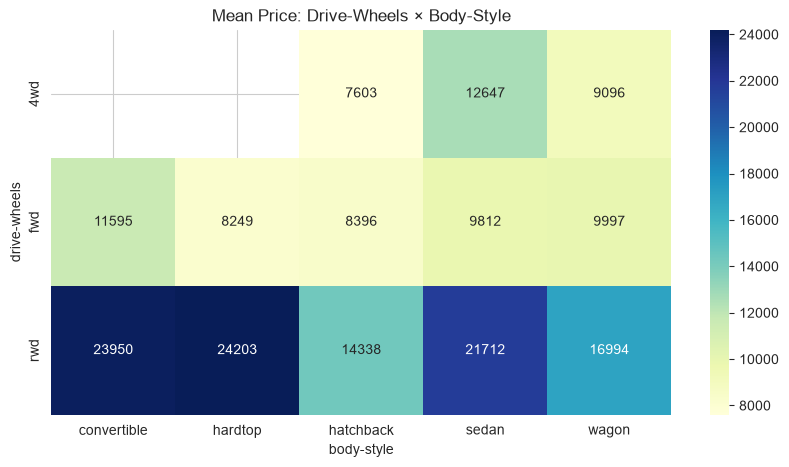

body-style,convertible,hardtop,hatchback,sedan,wagon
drive-wheels,,,,,
4wd,NaN,NaN,1.0,3.0,4.0
fwd,1.0,1.0,49.0,55.0,12.0
rwd,5.0,7.0,18.0,36.0,9.0


In [41]:
# 5.3 Two categorical variables vs price
pivot_two_cat = df.pivot_table(
    index="drive-wheels",
    columns="body-style",
    values="price",
    aggfunc="mean"
)

plt.figure(figsize=(10, 5))
sns.heatmap(pivot_two_cat, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Mean Price: Drive-Wheels × Body-Style")
plt.show()

# Count table to check reliability
count_two_cat = df.pivot_table(
    index="drive-wheels",
    columns="body-style",
    values="price",
    aggfunc="count"
)
display(count_two_cat)

Explanation:
This interaction heatmap shows that price depends on combinations of categories. For example, rwd convertibles/hardtops are expensive, while fwd hatchbacks are cheaper. Always check the count table because some combinations may have very few cars.

In [42]:
# 6. Question 5 — Main variables affecting price and feature selection
# 6.1 Correlation ranking
corr_rank = (
    df.select_dtypes(include=np.number)
      .corr()["price"]
      .drop("price")
      .sort_values(key=abs, ascending=False)
)
display(corr_rank.head(15))

engine-size          0.849061
curb-weight          0.834400
horsepower           0.804510
city-L/100km         0.789898
price_outlier        0.785580
width                0.738159
highway-mpg         -0.717409
length               0.690846
city-mpg            -0.690176
wheel-base           0.573278
bore                 0.543155
normalized-losses    0.140793
height               0.135486
diesel               0.110326
gas                 -0.110326
Name: price, dtype: float64

In [43]:
# 6.2 Mutual information and Random Forest feature importance
# Prepare features
drop_cols = ["price", "price_outlier", "city-L/100km", "horsepower-binned"]
X = df.drop(columns=drop_cols)
y = df["price"]

# One-hot encode categorical variables
X_encoded = pd.get_dummies(X, drop_first=True)

# Mutual information
mi = mutual_info_regression(X_encoded, y, random_state=42)
mi_series = pd.Series(mi, index=X_encoded.columns).sort_values(ascending=False)

print("Top mutual-information features:")
display(mi_series.head(15))

Top mutual-information features:


curb-weight         0.891727
horsepower          0.869684
highway-mpg         0.846218
engine-size         0.823076
city-mpg            0.759825
width               0.662841
wheel-base          0.579178
length              0.576950
bore                0.456855
stroke              0.372960
height              0.348482
fuel-system_2bbl    0.319383
drive-wheels_fwd    0.314634
fuel-system_mpfi    0.314363
drive-wheels_rwd    0.307172
dtype: float64

In [44]:
rf = RandomForestRegressor(
    n_estimators=500,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_encoded, y)

rf_importance = pd.Series(
    rf.feature_importances_,
    index=X_encoded.columns
).sort_values(ascending=False)

print("Top Random Forest feature importances:")
display(rf_importance.head(20))

Top Random Forest feature importances:


engine-size          0.636254
curb-weight          0.210048
highway-mpg          0.050617
horsepower           0.014354
width                0.013500
wheel-base           0.008993
make_bmw             0.007102
length               0.006914
normalized-losses    0.006753
city-mpg             0.006543
compression-ratio    0.005557
peak-rpm             0.004856
bore                 0.004838
height               0.004267
stroke               0.003259
engine-type_ohc      0.001443
fuel-system_mpfi     0.001229
aspiration_turbo     0.001055
symboling            0.001039
diesel               0.000929
dtype: float64

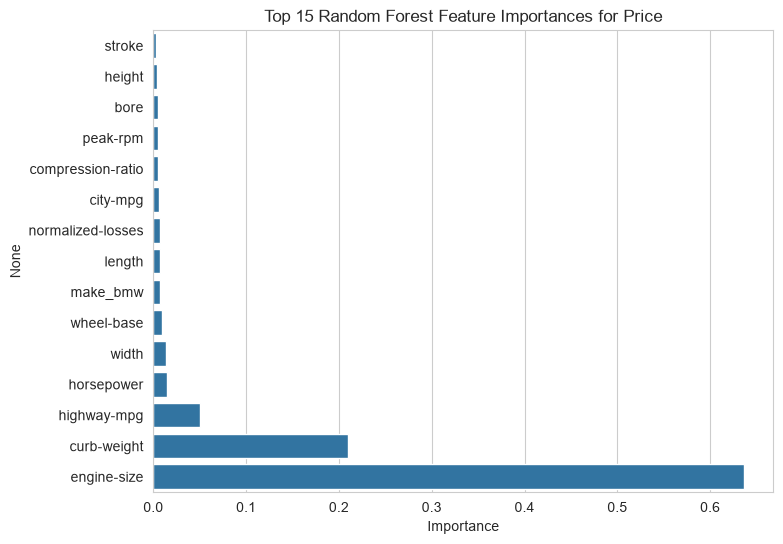

In [45]:
plt.figure(figsize=(8, 6))
top_imp = rf_importance.head(15).sort_values()
sns.barplot(x=top_imp.values, y=top_imp.index)
plt.title("Top 15 Random Forest Feature Importances for Price")
plt.xlabel("Importance")
plt.show()

Explanation:
Correlation, mutual information and Random Forest importance should consistently point to the same main variables:

engine-size

horsepower

curb-weight

width

length

wheel-base

city-mpg / highway-mpg — negative relationship

make

drive-wheels

body-style

num-of-cylinders

aspiration

city-L/100km and horsepower-binned are derived/redundant variables, so they are excluded from feature selection to avoid duplication.

7. Dealer pricing recommendation
Based on the EDA and feature-selection results:

Price premium should be attached to large engine size, high horsepower, heavy curb weight, larger width/length/wheel-base, rear-wheel drive, convertibles/hardtops, turbo aspiration, more cylinders, and premium makes.

Lower-priced inventory is typically front-wheel drive, small hatchbacks, low horsepower, small engine size and high fuel economy.

Fuel economy is negatively related to price in this dataset: economical small cars are cheaper, while powerful cars are more expensive.

The dealer should use a segmented pricing strategy:

Premium/sports/luxury segment: price based on horsepower, engine size, drivetrain, body style and make.

Economy/compact segment: price based on fuel economy, smaller engine size and hatchback/sedan body style.

Because make and some category combinations have small sample sizes, the dealer should combine statistical estimates with market knowledge and inspect group counts before setting prices.